# Airbnb NYC Market Analysis

In this project, we will look at Airbnb listings in New York City. Airbnb offers different types of accommodation, from private rooms to entire apartments. Prices can vary depending on the location and type of accommodation.
We want to find out which areas of New York City have the most listings, where accommodation is the most expensive, and what factors might be related to the price.
Our goal is to better understand the Airbnb market in New York City and see how listings differ across different areas of the city.

## Opening and Exploring the Data

First, we will import the libraries and load the Airbnb dataset. Then, we will look at the first few rows to see what information is available.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (12,6)

In [3]:
from pathlib import Path
csv_path = Path.home() / "Desktop" / "AB_NYC_2019.csv"
df = pd.read_csv(csv_path)
df.head()


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## Exploring the Dataset
First, let's take a look at our data. We will check the size of the dataset, the column types, and see if there are any missing values.

In [5]:
df.shape

(48895, 16)

In [51]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

In [7]:
df.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

## Cleaning the Data

In [8]:
df.loc[df["last_review"].isna(), "number_of_reviews"].value_counts()


number_of_reviews
0    10052
Name: count, dtype: int64

In [14]:

df["reviews_per_month"] = df["reviews_per_month"].fillna(0)


In [15]:

df["name"] = df["name"].fillna("Unknown")
df["host_name"] = df["host_name"].fillna("Unknown")


In [16]:
df.isnull().sum()

id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                     0
calculated_host_listings_count        0
availability_365                      0
dtype: int64

### Missing values
We still have some missing values in reviews_per_month. Since these listings have no reviews, we can replace the missing values with 0.

In [17]:
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)
df.isnull().sum()

id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                     0
calculated_host_listings_count        0
availability_365                      0
dtype: int64

### Duplicate Rows

In [18]:
df.duplicated().sum()

0

### Checking Prices 
Now let's look at the prices. We want to see the average price, the lowest and highest prices, and whether there are any unusual values.

In [20]:
df["price"].describe()

count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

We found no duplicate rows.

The average price is 153 dolars , but most listings are cheaper, with a median price of 106 dolars . Prices range from 0 to $10,000, so we should check these values before continuing.

### Checking Unusual Prices
First, let's see how many listings have a price of $0.
df[df["price"] == 0].shape[0]


In [21]:

df[df["price"] == 0].shape[0]


11

In [22]:
df[df["price"] > 1000].shape[0]

239

We found 11 listings with a price of 0 and 239 listings costing more than $1,000.

We'll remove the listings with a price of $0, but keep the expensive ones for now.

In [23]:
df = df[df["price"] > 0].copy()
df.shape

(48884, 16)

## Listings by Borough

Let's see how Airbnb listings are spread across New York City and which borough has the most listings.

In [24]:
df["neighbourhood_group"].value_counts()

neighbourhood_group
Manhattan        21660
Brooklyn         20095
Queens            5666
Bronx             1090
Staten Island      373
Name: count, dtype: int64

This will show the number of Airbnb listings in Manhattan, Brooklyn, Queens, the Bronx, and Staten Island.

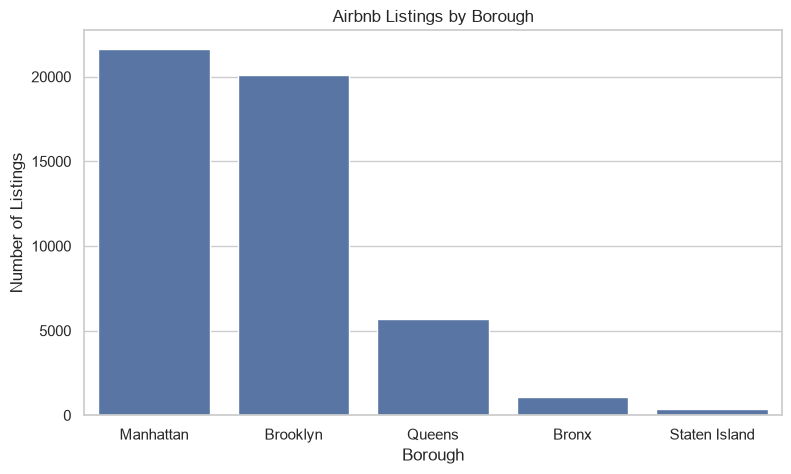

In [26]:

borough_counts = df["neighbourhood_group"].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=borough_counts.index, y=borough_counts.values)

plt.title("Airbnb Listings by Borough")
plt.xlabel("Borough")
plt.ylabel("Number of Listings")
plt.show()


Manhattan has the most Airbnb listings, followed closely by Brooklyn. Queens has fewer listings, while the Bronx and Staten Island have the smallest numbers.

Most Airbnb listings in New York City are located in Manhattan and Brooklyn.

## Prices by Borough

We have seen where most Airbnb listings are located. Now let's check which boroughs are more expensive.

In [27]:
df.groupby("neighbourhood_group")["price"].agg(["mean", "median"]).round(2)

,mean,median
neighbourhood_group,,
Bronx,87.58,65.0
Brooklyn,124.44,90.0
Manhattan,196.88,150.0
Queens,99.52,75.0
Staten Island,114.81,75.0


Manhattan has the highest prices, with an average of about 197 dollars per night. The Bronx is the cheapest, with an average of around 88 dollars.

In every borough, the average price is higher than the median. This suggests that some expensive listings are pulling the average up.

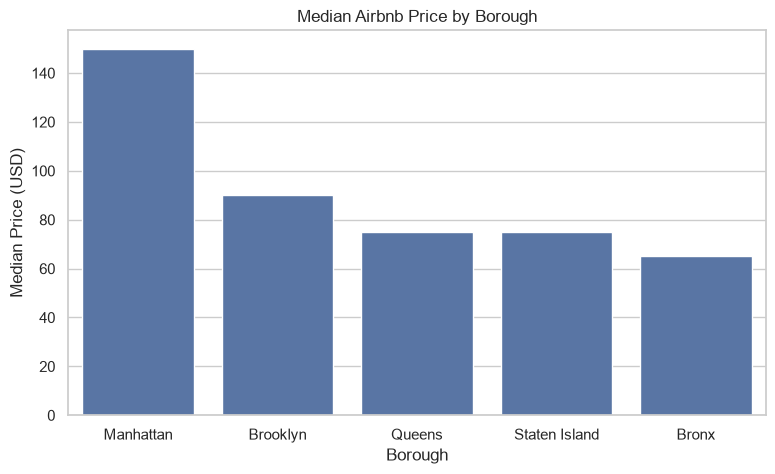

In [28]:

borough_prices = (
    df.groupby("neighbourhood_group")["price"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=borough_prices.index, y=borough_prices.values)

plt.title("Median Airbnb Price by Borough")
plt.xlabel("Borough")
plt.ylabel("Median Price (USD)")
plt.show()


Manhattan is the most expensive borough, with a median price of 150 dollars per night. Brooklyn comes next at 90 dollars, while the Bronx has the lowest median price at 65 dollars.

## Room Types

Airbnb offers different types of accommodation. Let's see which room types are the most common in New York City.

In [29]:
df["room_type"].value_counts()

room_type
Entire home/apt    25407
Private room       22319
Shared room         1158
Name: count, dtype: int64

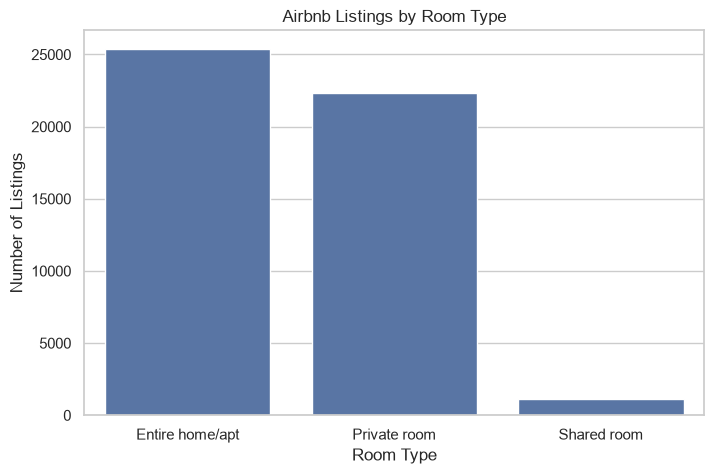

In [30]:
room_counts = df["room_type"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=room_counts.index, y=room_counts.values)

plt.title("Airbnb Listings by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")
plt.show()


Entire homes and apartments are the most common, with 25,407 listings. Private rooms are also popular, with 22,319 listings. Shared rooms are much less common, with only 1,158 listings.

### Prices by Room Type
Let's check how much each room type costs and whether renting an entire apartment is more expensive than renting a private room.

In [31]:
df.groupby("room_type")["price"].agg(["mean", "median"]).round(2)

,mean,median
room_type,,
Entire home/apt,211.81,160.0
Private room,89.81,70.0
Shared room,70.25,45.0


Entire homes and apartments are the most expensive, with a median price of 160 dollars per night. Private rooms cost around 70 dollars, while shared rooms are the cheapest at 45 dollars.

The type of accommodation seems to make a big difference in price.

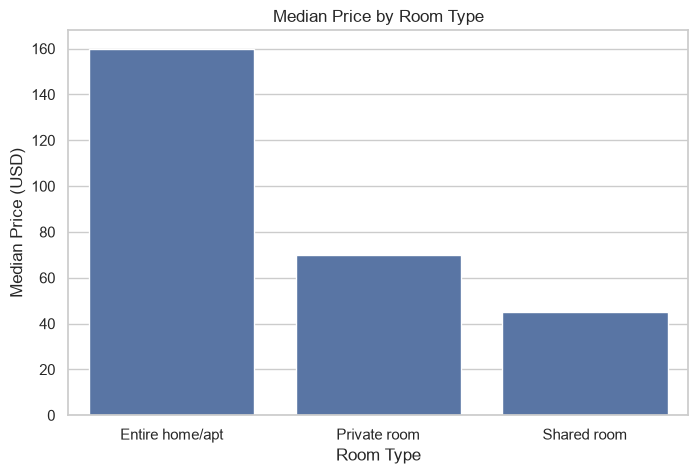

In [32]:

room_prices = (
    df.groupby("room_type")["price"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=room_prices.index, y=room_prices.values)

plt.title("Median Price by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Median Price (USD)")
plt.show()


Entire homes and apartments have the highest median price at 160 dollars per night. Private rooms cost 70 dollars, while shared rooms cost 45 dollars.

Renting an entire apartment is more than twice as expensive as renting a private room.

## Reviews and Prices

Let's see if there is a relationship between the number of reviews and the price of a listing.

In [33]:
df["number_of_reviews"].corr(df["price"])

-0.04792566604580439

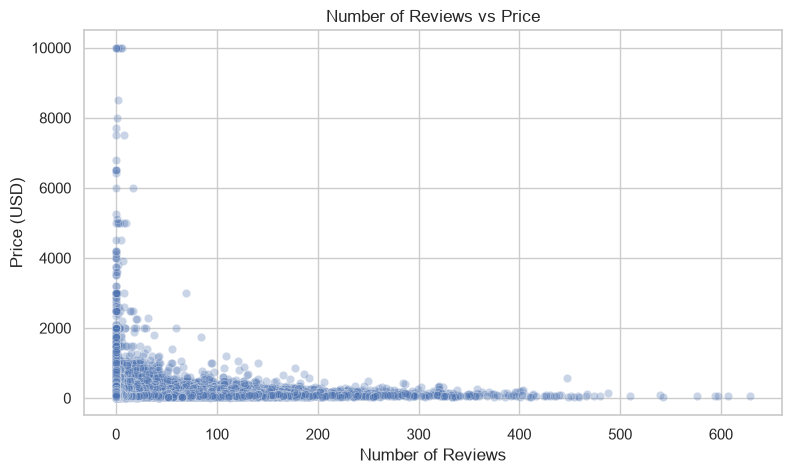

In [34]:

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="number_of_reviews",
    y="price",
    alpha=0.3
)

plt.title("Number of Reviews vs Price")
plt.xlabel("Number of Reviews")
plt.ylabel("Price (USD)")
plt.show()


The correlation between price and number of reviews is -0.048, which is very weak.

The chart also shows that expensive listings often have fewer reviews, but overall, there is no clear relationship between price and the number of reviews.

## Minimum Nights

Some Airbnb listings require guests to stay for several nights. Let's see what the minimum stay looks like across New York City.

In [35]:
df["minimum_nights"].describe()

count    48884.000000
mean         7.029887
std         20.512224
min          1.000000
25%          1.000000
50%          3.000000
75%          5.000000
max       1250.000000
Name: minimum_nights, dtype: float64

In [36]:
df["minimum_nights"].value_counts().head(10)

minimum_nights
1     12717
2     11693
3      7998
30     3758
4      3302
5      3033
7      2058
6       752
14      562
10      483
Name: count, dtype: int64

Most listings require a minimum stay of 1 to 3 nights. The median is 3 nights, but some listings have much longer minimum stays.

The highest value is 1,250 nights, which is unusually high.

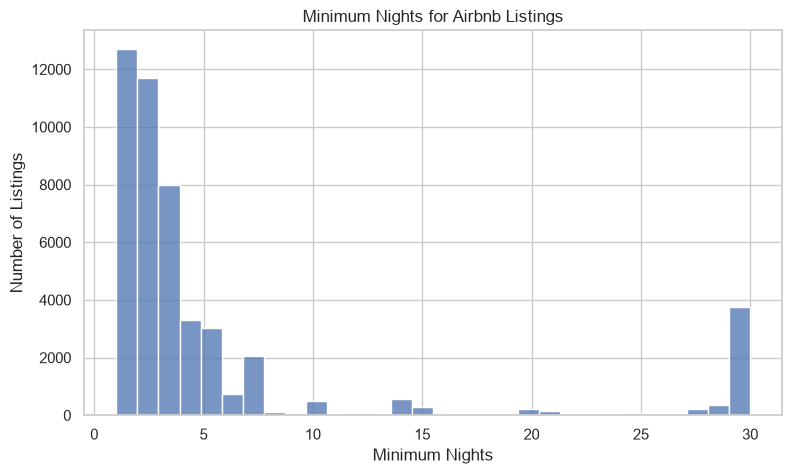

In [37]:
short_stays = df[df["minimum_nights"] <= 30]

plt.figure(figsize=(9, 5))
sns.histplot(data=short_stays, x="minimum_nights", bins=30)

plt.title("Minimum Nights for Airbnb Listings")
plt.xlabel("Minimum Nights")
plt.ylabel("Number of Listings")
plt.show()


Most Airbnb listings have a minimum stay of 1 to 3 nights. There are also quite a few listings that require at least 30 nights.

Short stays are much more common than longer ones.

## Availability
Some Airbnb listings are available throughout the year, while others are only available for a few days. Let's see how availability differs between listings.

In [38]:
df["availability_365"].describe()

count    48884.000000
mean       112.779498
std        131.627271
min          0.000000
25%          0.000000
50%         45.000000
75%        227.000000
max        365.000000
Name: availability_365, dtype: float64

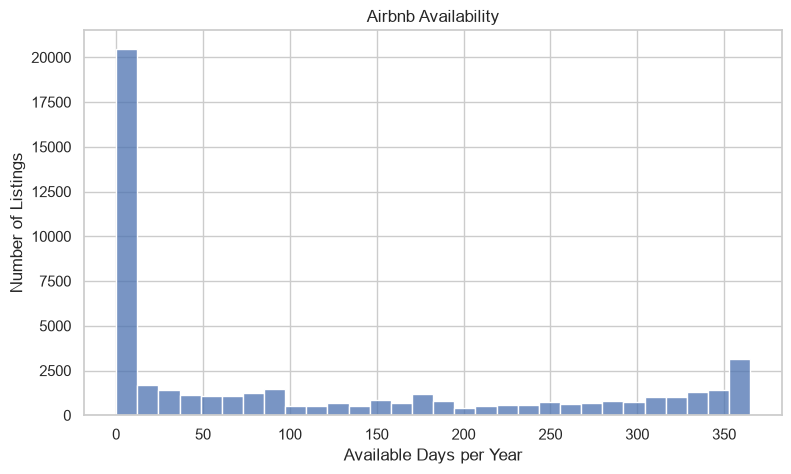

In [39]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="availability_365", bins=30)

plt.title("Airbnb Availability")
plt.xlabel("Available Days per Year")
plt.ylabel("Number of Listings")
plt.show()


A large number of listings have 0 available days. Some listings are available for most of the year, while others are only available for a few days.

Availability varies a lot between listings.

## Prices and Availability

Let's check if there is a relationship between the price of a listing and how many days it is available.

In [40]:
df["price"].corr(df["availability_365"])

0.08184749749030196

In [41]:
df["availability_group"] = pd.cut(
    df["availability_365"],
    bins=[-1, 0, 90, 180, 270, 365],
    labels=["0 days", "1-90", "91-180", "181-270", "271-365"]
)

df.groupby("availability_group", observed=True)["price"].median()


availability_group
0 days     100.0
1-90       100.0
91-180     110.0
181-270    125.0
271-365    120.0
Name: price, dtype: float64

The correlation between price and availability is 0.082, which is very weak.

Listings available for up to 90 days have a median price of 100 dollars, while those available for 181–270 days have a median price of 125 dollars.

Overall, availability doesn't seem to have a strong relationship with price.

## Most Expensive Neighbourhoods

Prices can be different even within the same borough. Let's see which neighbourhoods have the highest prices.

In [42]:
neighbourhood_prices = (
    df.groupby("neighbourhood")["price"]
    .agg(["count", "median"])
)

neighbourhood_prices = neighbourhood_prices[
    neighbourhood_prices["count"] >= 20
]

neighbourhood_prices.sort_values("median", ascending=False).head(10)


,count,median
neighbourhood,,
Tribeca,177,295.0
NoHo,78,250.0
Flatiron District,80,225.0
Midtown,1545,210.0
Financial District,744,200.0
West Village,768,200.0
SoHo,358,199.0
Chelsea,1113,199.0
Greenwich Village,392,197.5


Tribeca has the highest median price at 295 dollars per night, followed by NoHo at 250 dollars and the Flatiron District at 225 dollars.

All 10 neighbourhoods in the table are in Manhattan, which also had the highest prices in our earlier comparison.

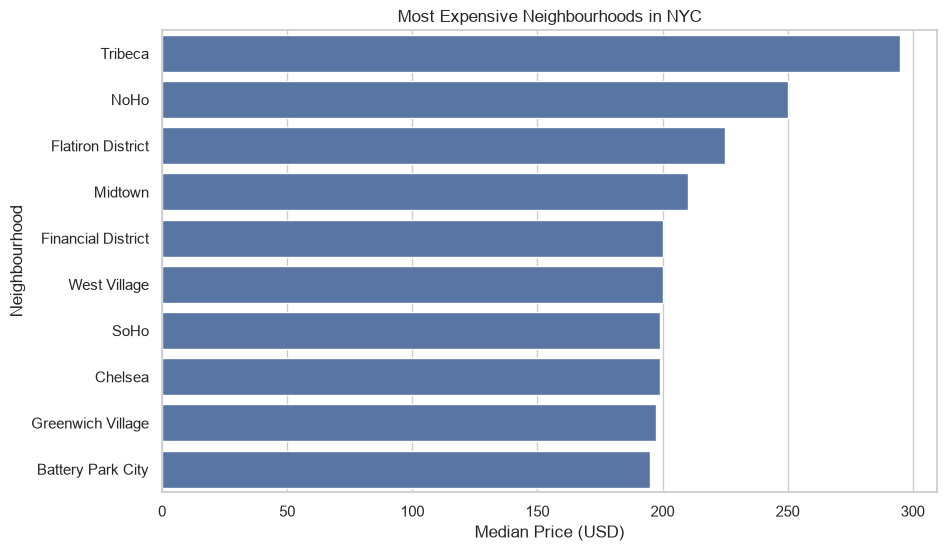

In [43]:
top_neighbourhoods = (
    neighbourhood_prices
    .sort_values("median", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_neighbourhoods["median"],
    y=top_neighbourhoods.index
)

plt.title("Most Expensive Neighbourhoods in NYC")
plt.xlabel("Median Price (USD)")
plt.ylabel("Neighbourhood")
plt.show()


## Airbnb Prices on the Map
We already know that Manhattan has the highest prices. Now let's see where expensive and cheaper listings are located across New York City.

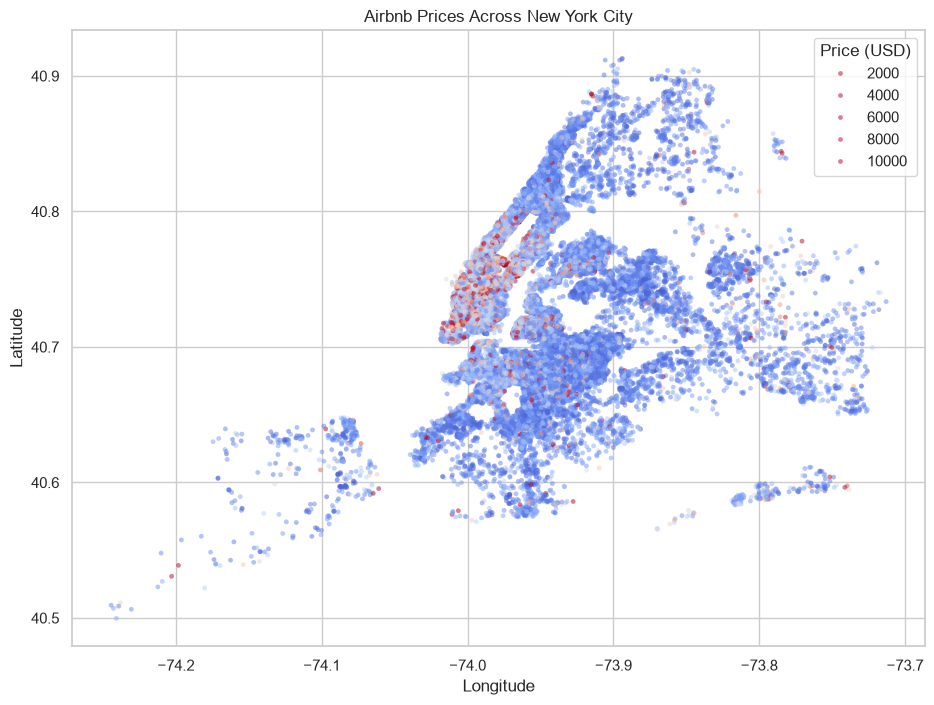

In [44]:
plt.figure(figsize=(11, 8))

sns.scatterplot(
    data=df,
    x="longitude",
    y="latitude",
    hue="price",
    hue_norm=(0, 500),
    palette="coolwarm",
    s=12,
    alpha=0.5,
    linewidth=0
)

plt.title("Airbnb Prices Across New York City")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Price (USD)")
plt.show()


## Expensive Listings by Borough

Let's check which boroughs have the highest percentage of listings costing more than 200 dollars per night.

In [47]:
expensive_share = (
    df.assign(expensive=df["price"] > 200)
    .groupby("neighbourhood_group")["expensive"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

expensive_share.round(1)


neighbourhood_group
Manhattan        27.4
Brooklyn         10.2
Staten Island     6.7
Queens            5.7
Bronx             4.1
Name: expensive, dtype: float64

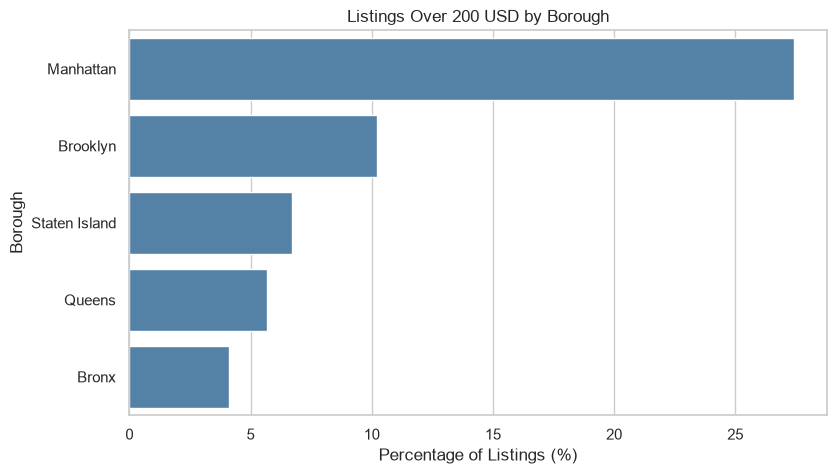

In [48]:

plt.figure(figsize=(9, 5))

sns.barplot(
    x=expensive_share.values,
    y=expensive_share.index,
    color="steelblue"
)

plt.title("Listings Over 200 USD by Borough")
plt.xlabel("Percentage of Listings (%)")
plt.ylabel("Borough")
plt.show()


The map shows that Airbnb listings are concentrated in Manhattan and Brooklyn. Higher-priced listings also appear more often in Manhattan.

Manhattan has the highest percentage of listings costing more than $200 per night (27.4%). Brooklyn comes second with 10.2%, while the Bronx has the lowest percentage at 4.1%.

This shows that expensive listings are much more common in Manhattan than in other boroughs.

## Prices by Borough and Room Type

We have compared prices by borough and room type separately. Now let's combine them to see how much different types of accommodation cost in each borough.

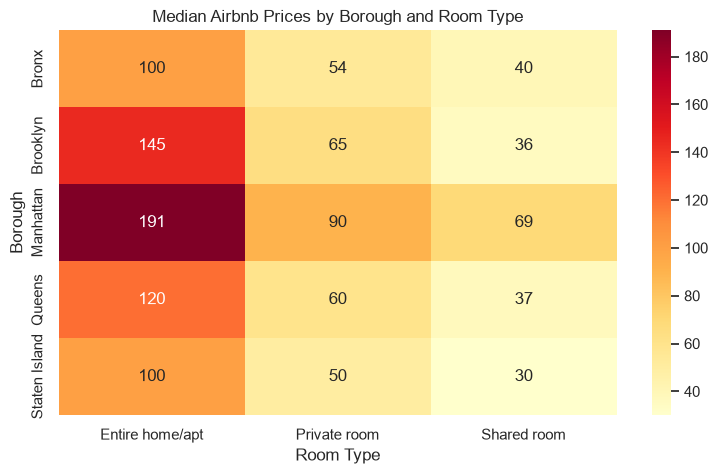

In [49]:
price_table = df.pivot_table(
    values="price",
    index="neighbourhood_group",
    columns="room_type",
    aggfunc="median"
)

plt.figure(figsize=(9, 5))

sns.heatmap(
    price_table,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd"
)

plt.title("Median Airbnb Prices by Borough and Room Type")
plt.xlabel("Room Type")
plt.ylabel("Borough")
plt.show()


Manhattan is the most expensive borough for all three room types. An entire apartment costs around $191 per night, compared to $145 in Brooklyn and $100 in the Bronx.

Shared rooms are the cheapest option in every borough. The lowest median price is $30 on Staten Island.

Both location and room type seem to be important when comparing Airbnb prices.

## Price Distribution by Borough

We have compared median prices, but prices can also vary a lot within the same borough.

Let's use a boxplot to see how prices are distributed and compare the differences between boroughs.

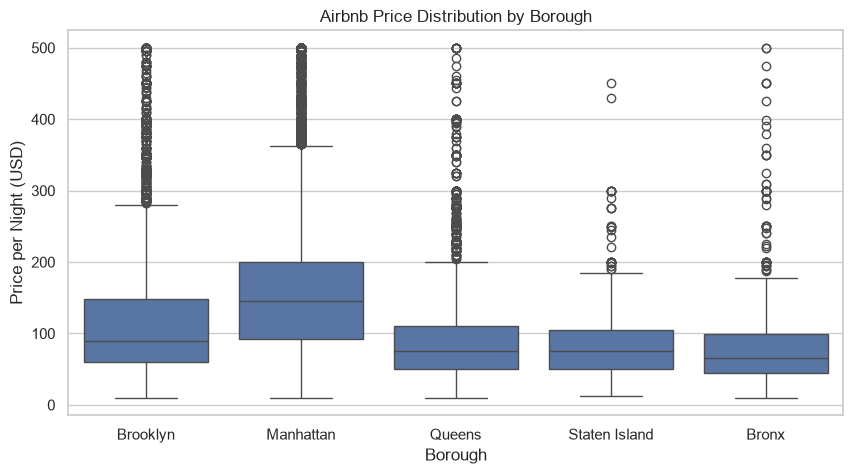

In [50]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df[df["price"] <= 500],
    x="neighbourhood_group",
    y="price"
)

plt.title("Airbnb Price Distribution by Borough")
plt.xlabel("Borough")
plt.ylabel("Price per Night (USD)")
plt.show()


Manhattan has the highest prices and the largest spread of prices. Brooklyn is also quite expensive, while Queens, the Bronx and Staten Island are generally cheaper.

There are many outliers, especially in Manhattan and Brooklyn. This means that some listings are much more expensive than most others in the same borough.

The boxplot only shows listings priced at $500 or less to make the differences easier to see.

## Comparing Entire Apartments

We have seen that Manhattan is the most expensive borough overall. Now let's compare only entire homes and apartments to see whether the same pattern appears.

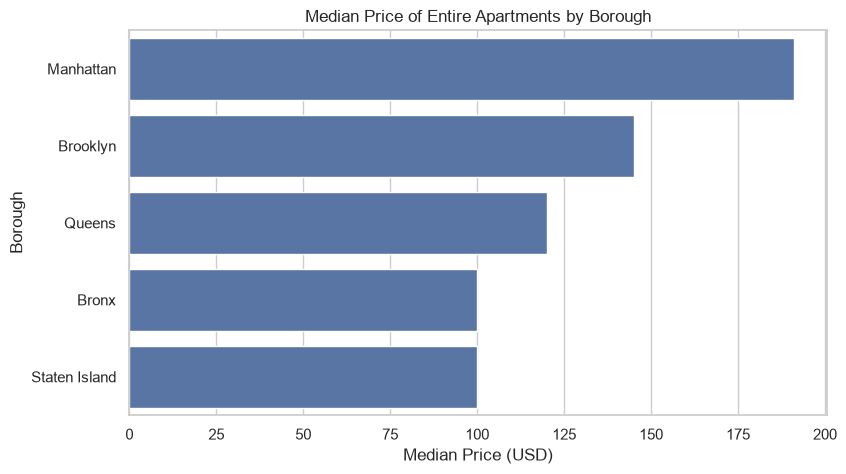

In [51]:
apartments = df[df["room_type"] == "Entire home/apt"]

apartment_prices = (
    apartments.groupby("neighbourhood_group")["price"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=apartment_prices.values, y=apartment_prices.index)

plt.title("Median Price of Entire Apartments by Borough")
plt.xlabel("Median Price (USD)")
plt.ylabel("Borough")
plt.show()


Manhattan has the highest median price for entire apartments at 191 dolars  per night, followed by Brooklyn at 145 dolars and Queens at 120dolars .

The Bronx and Staten Island are the cheapest, with a median price of $100.

Even when comparing the same type of accommodation, prices are much higher in Manhattan.

## What Drives Airbnb Prices?

We have already seen that Airbnb prices are different across boroughs and room types.

Now, let's check which other factors might be related to the price. We will start by looking at correlations between numerical variables.

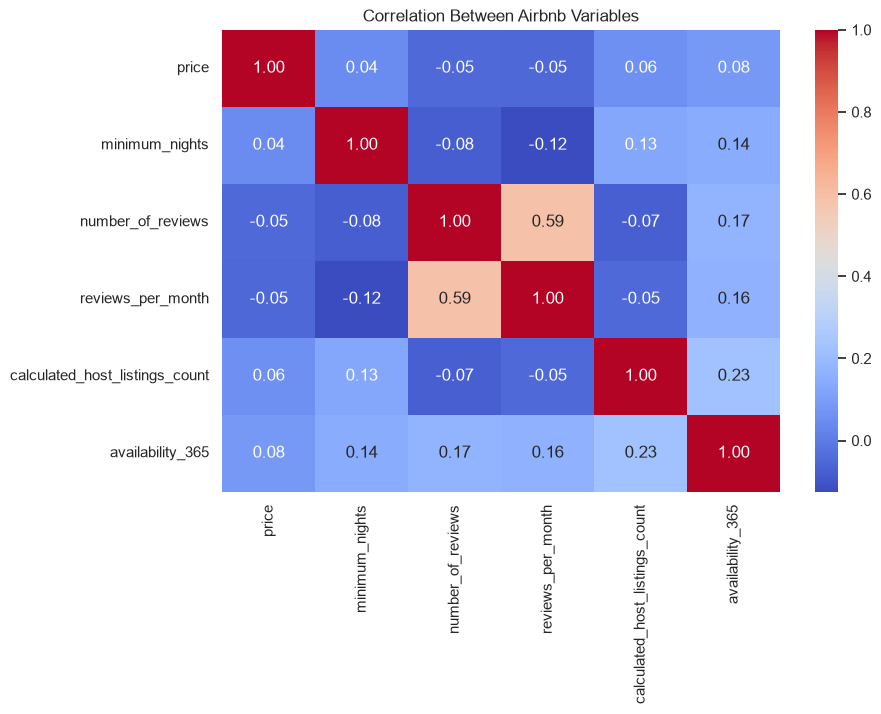

In [52]:
columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

correlation = df[columns].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Between Airbnb Variables")
plt.show()

The correlations between price and the other numerical variables are very weak. All values are close to zero.
The strongest correlation in the table is between the number of reviews and reviews per month (0.59).
This suggests that numerical variables alone may not explain Airbnb prices very well. Location and room type could be more important, so we will include them in our regression model.

## Multiple Linear Regression

We have already compared prices across boroughs and room types. Now, let's see how several factors are related to price at the same time.
We will use multiple linear regression to understand which variables are associated with higher or lower Airbnb prices.
We will also check how well the model explains differences in prices.

In [54]:
import statsmodels.api as sm

features = [
    "minimum_nights",
    "number_of_reviews",
    "availability_365",
    "neighbourhood_group",
    "room_type"
]

model_df = df[features + ["price"]].dropna().copy()

X = pd.get_dummies(
    model_df[features],
    columns=["neighbourhood_group", "room_type"],
    drop_first=True,
    dtype=int
)

X = sm.add_constant(X)
y = model_df["price"]

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.092
Method:                 Least Squares   F-statistic:                     553.3
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:31:30   Log-Likelihood:            -3.3494e+05
No. Observations:               48884   AIC:                         6.699e+05
Df Residuals:                   48874   BIC:                         6.700e+05
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const 

The model has an R² of 0.092, which means it explains only 9.2% of the variation in Airbnb prices.
Location and room type seem to be important. For example, listings in Manhattan are more expensive than those in the Bronx, while private and shared rooms are cheaper than entire apartments.
Most of these differences are statistically significant (p-value below 0.05).
However, the R² is quite low, so the model does not explain prices very well. We may need more variables to improve it.

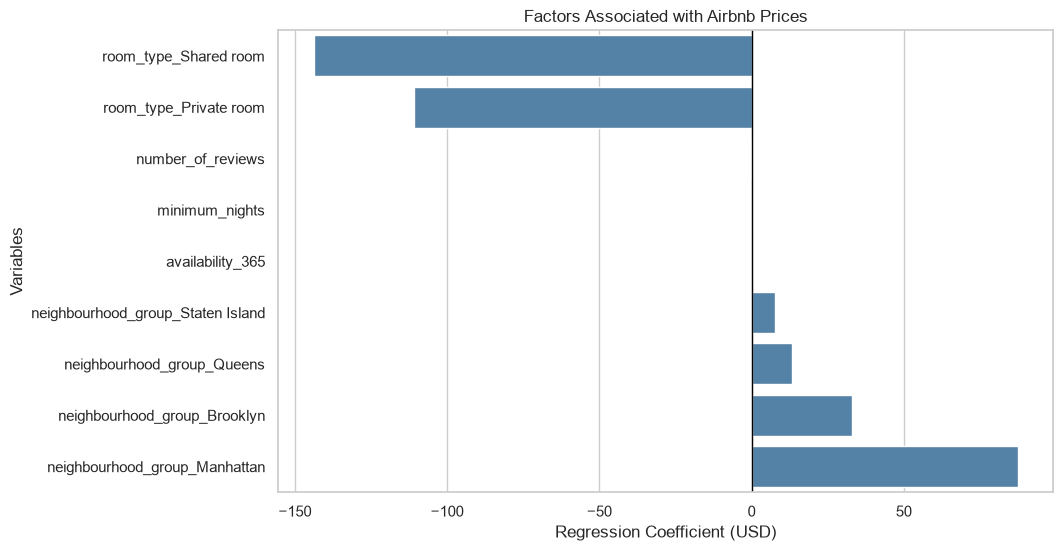

In [55]:
coefficients = model.params.drop("const").sort_values()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=coefficients.values,
    y=coefficients.index,
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Factors Associated with Airbnb Prices")
plt.xlabel("Regression Coefficient (USD)")
plt.ylabel("Variables")
plt.show()

The chart shows how different variables are associated with Airbnb prices.
Room type and location have the largest coefficients. Private and shared rooms are cheaper than entire apartments, while listings in Manhattan and Brooklyn are more expensive than those in the Bronx.
The number of reviews, minimum nights and availability have much smaller coefficients.
However, these variables use different units, so we cannot directly compare their importance based only on the size of the coefficients.

### Improving the Regression Model

Our first regression model had a low R² score. This means that the variables we used explain only a small part of the differences in Airbnb prices.
Some listings are much more expensive than others. To reduce the influence of these extreme values, we will try using the logarithm of price and compare the results.

In [56]:
import numpy as np
import statsmodels.api as sm

df_log = df[df["price"] > 0].copy()

df_log["log_price"] = np.log(df_log["price"])

X_log = pd.get_dummies(
    df_log[
        ["minimum_nights", "number_of_reviews",
         "availability_365", "neighbourhood_group", "room_type"]
    ],
    drop_first=True,
    dtype=float
)

X_log = sm.add_constant(X_log)
y_log = df_log["log_price"]

log_model = sm.OLS(y_log, X_log).fit()

print(log_model.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.473
Model:                            OLS   Adj. R-squared:                  0.473
Method:                 Least Squares   F-statistic:                     4872.
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:35:18   Log-Likelihood:                -36151.
No. Observations:               48884   AIC:                         7.232e+04
Df Residuals:                   48874   BIC:                         7.241e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const 

After applying the logarithm to the price, the model achieved an R² of 0.473. This means it explains about 47% of the variation in log prices.
Location and room type are still strongly associated with Airbnb prices. Listings in Manhattan and Brooklyn tend to be more expensive, while private and shared rooms tend to be cheaper than entire apartments.
Most variables are statistically significant, but Staten Island is not.
The results look promising, although we need to evaluate both models on the original price scale before deciding which one predicts prices better.

In [58]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Predictions from both models
pred_original = model.predict(X)
pred_log = np.exp(log_model.predict(X_log))

# Compare errors in USD
comparison = pd.DataFrame({
    "Model": ["Original Price", "Log Price"],
    "MAE": [
        mean_absolute_error(df["price"], pred_original),
        mean_absolute_error(df_log["price"], pred_log)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(df["price"], pred_original)),
        np.sqrt(mean_squared_error(df_log["price"], pred_log))
    ]
})

display(comparison.round(2))

,Model,MAE,RMSE
0,Original Price,73.95,228.80
1,Log Price,64.13,230.62


The log-price model has a lower MAE (64.13 USD) than the original model (73.95 USD). This means its predictions are closer to actual prices on average.
However, the original model has a slightly lower RMSE (228.80 USD compared to 230.62 USD).
The results suggest that the log-price model reduces the average absolute error, but it does not perform better on every metric.
These results are based on the training data, so we still need to test both models on unseen data.

In [59]:
from sklearn.model_selection import train_test_split

In [60]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import statsmodels.api as sm

features = [
    "minimum_nights",
    "number_of_reviews",
    "availability_365",
    "neighbourhood_group",
    "room_type"
]

data = df[df["price"] > 0].dropna(
    subset=features + ["price"]
).copy()

X = pd.get_dummies(data[features], drop_first=True, dtype=float)
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

model_price = sm.OLS(y_train, X_train).fit()
model_log = sm.OLS(np.log(y_train), X_train).fit()

pred_price = model_price.predict(X_test)
pred_log = np.exp(model_log.predict(X_test))

results = pd.DataFrame({
    "Model": ["Original Price", "Log Price"],
    "MAE": [
        mean_absolute_error(y_test, pred_price),
        mean_absolute_error(y_test, pred_log)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, pred_price)),
        np.sqrt(mean_squared_error(y_test, pred_log))
    ]
})

display(results.round(2))

,Model,MAE,RMSE
0,Original Price,72.82,187.69
1,Log Price,62.99,189.85


## Conclusions

In this project, we looked at Airbnb listings in New York City to see what affects their prices.
We found that prices vary depending on the location and room type. Manhattan is the most expensive area, while the Bronx and Staten Island are generally cheaper. Entire apartments also cost more than private and shared rooms.
We also built two regression models to see how well we could predict Airbnb prices.
The results on the test data were:

- Original Price: MAE = 72.82 USD, RMSE = 187.69 USD
- Log Price: MAE = 62.99 USD, RMSE = 189.85 USD

The log-price model had a lower MAE, while the original model had a slightly lower RMSE.
The models were not very accurate, especially for more expensive listings. However, the analysis showed us which factors are related to Airbnb prices and how much prices can differ across New York City.